## 6600 Project1_WFM vs BTO

In [1]:
import pandas as pd
#dataframe  = pd.read_excel('peppers.xlsx')
file_path = "WFHtimeseries_monthly.xlsx"
sheet_name = "Full Remote-Hybrid-Full Onsite"

df = pd.read_excel(file_path, sheet_name=sheet_name)
df.head()

,date,full_onsite_curr,hybrid_curr,full_remote_curr,full_onsite_curr_e,hybrid_curr_e,full_remote_curr_e,Notes,License,Citation
0,2021-11-01,54.361965,30.379524,15.258510,30.897287,45.261566,23.841146,NaN,"Copyright 2025 by Jose Maria Barrero, Nicholas...","When using this work, please cite: Barrero, J..."
1,2021-12-01,53.439350,32.561432,13.999217,29.128979,49.562496,21.308525,NaN,NaN,NaN
2,2022-01-01,56.790363,25.459003,17.750633,32.101810,40.005432,27.892756,NaN,NaN,NaN
3,2022-02-01,59.484886,22.782024,17.733088,31.127356,38.727726,30.144917,NaN,NaN,NaN
4,2022-03-01,57.281601,27.246471,15.471930,30.511538,44.320839,25.167624,NaN,NaN,NaN


### by month

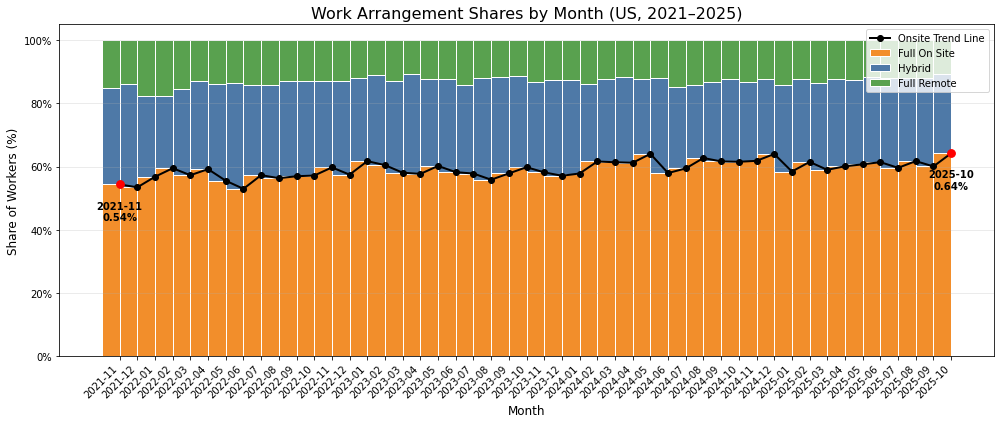

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Load data from Excel
file_path = "WFHtimeseries_monthly.xlsx"
sheet_name = "Full Remote-Hybrid-Full Onsite"

df = pd.read_excel(file_path, sheet_name=sheet_name)

# Ensure date column is datetime
df["date"] = pd.to_datetime(df["date"])

# Create YYYY-MM month string
df["month"] = df["date"].dt.to_period("M").astype(str)

# Group by month
grouped = (
    df.groupby("month")[["full_onsite_curr", "hybrid_curr", "full_remote_curr"]]
      .mean()
      .sort_index()
)

# Define consistent colors
colors = {
    "full_onsite_curr": "#F28E2B",   # orange
    "hybrid_curr": "#4E79A7",        # blue
    "full_remote_curr": "#59A14F",   # green
}

months = grouped.index.tolist()
n_months = len(months)

# For Marimekko (equal width per month)
widths = [1] * n_months

onsite_share = grouped["full_onsite_curr"].values / 100
hybrid_share = grouped["hybrid_curr"].values / 100
remote_share = grouped["full_remote_curr"].values / 100

# Build x positions for Marimekko
left = 0
left_edges = []
centers = []
for w in widths:
    left_edges.append(left)
    centers.append(left + w / 2.0)
    left += w

# --------- Create figure: ONLY Marimekko + Onsite line ---------
fig, ax = plt.subplots(figsize=(14, 6))

# ----- Marimekko (stacked bars) -----
for i in range(n_months):
    # Full Onsite stack
    ax.bar(
        left_edges[i],
        onsite_share[i],
        width=widths[i],
        color=colors["full_onsite_curr"],
        edgecolor="white",
        label="Full On Site" if i == 0 else ""
    )
    # Hybrid stack
    ax.bar(
        left_edges[i],
        hybrid_share[i],
        width=widths[i],
        bottom=onsite_share[i],
        color=colors["hybrid_curr"],
        edgecolor="white",
        label="Hybrid" if i == 0 else ""
    )
    # Full Remote stack
    ax.bar(
        left_edges[i],
        remote_share[i],
        width=widths[i],
        bottom=onsite_share[i] + hybrid_share[i],
        color=colors["full_remote_curr"],
        edgecolor="white",
        label="Full Remote" if i == 0 else ""
    )

# ----- Add onsite line ABOVE Marimekko -----
ax.plot(
    centers,
    grouped["full_onsite_curr"] / 100,
    marker="o",
    linewidth=2,
    color="black",
    label="Onsite Trend Line"  # legend name
)

# ----- Add annotation for 202111 & 202510 -----

target_months = ["2021-11", "2025-10"]

for tm in target_months:
    if tm in grouped.index:
        idx = grouped.index.tolist().index(tm)
        x = centers[idx]
        y = onsite_share[idx]
        
        ax.text(
            x, y - 0.12,                  # adjust the dot position
            f"{tm}\n{y:.2f}%",            # show month + onsite value 
            ha="center", va="bottom",
            fontsize=10, fontweight="bold",
            color="black"
        )
        ax.scatter(x, y, color="red", s=60, zorder=5)  # highlight point


# ----- Format axis -----
ax.set_xlabel("Month", fontsize=12)
ax.set_ylabel("Share of Workers (%)", fontsize=12)
ax.yaxis.set_major_formatter(PercentFormatter(1.0)) # show 0–1 as %
ax.set_xticks(centers)                              # set month positions
ax.set_xticklabels(months, rotation=45, ha="right") # rotate labels
ax.set_title("Work Arrangement Shares by Month (US, 2021–2025)", fontsize=16) # title

ax.legend(loc="upper right")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


### By year

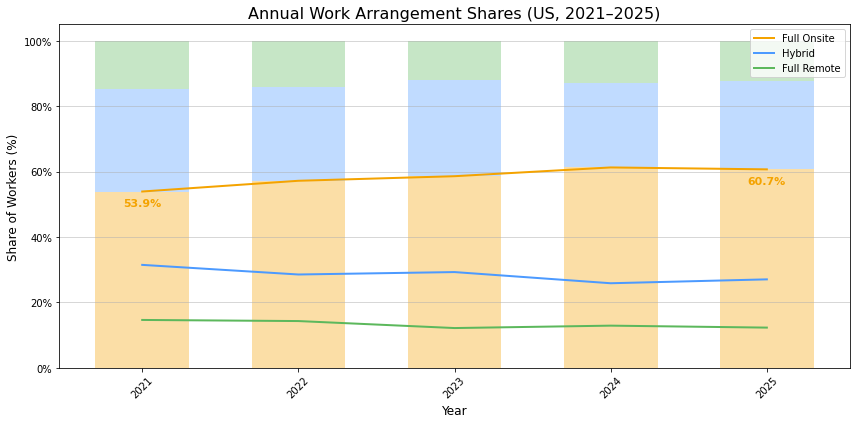

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Ensure date is datetime
df["date"] = pd.to_datetime(df["date"])

# Extract year
df["year"] = df["date"].dt.year

# Aggregate yearly average of the 3 columns (full onsite / hybrid / full remote）
yearly = df.groupby("year")[["full_onsite_curr", "hybrid_curr", "full_remote_curr"]].mean()

# -------------------------------------------------------------
# Colors (consistent colors)
# -------------------------------------------------------------
color_onsite = "#F4A300"      # gold
color_hybrid = "#4C9AFF"      # blue
color_remote = "#5CB85C"      # green

# -------------------------------------------------------------
# Plot: Line chart + Marimekko (stacked bar as proxy 用等寬 stacked bar 模擬）
# -------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

years = yearly.index.astype(str)

# ----- Line Chart -----
ax.plot(years, yearly["full_onsite_curr"], label="Full Onsite", color=color_onsite, linewidth=2)
ax.plot(years, yearly["hybrid_curr"], label="Hybrid", color=color_hybrid, linewidth=2)
ax.plot(years, yearly["full_remote_curr"], label="Full Remote", color=color_remote, linewidth=2)

# ----- Marimekko-like stacked bars -----
bar_width = 0.6
ax.bar(years, yearly["full_onsite_curr"], width=bar_width, color=color_onsite, alpha=0.35)
ax.bar(years, yearly["hybrid_curr"], width=bar_width, bottom=yearly["full_onsite_curr"],
       color=color_hybrid, alpha=0.35)
ax.bar(years,
       yearly["full_remote_curr"], width=bar_width,
       bottom=yearly["full_onsite_curr"] + yearly["hybrid_curr"],
       color=color_remote, alpha=0.35)

# ----- Format y-axis to percentage -----
ax.yaxis.set_major_formatter(PercentFormatter(100))

# ----- Add annotations for Onsite 2021 & 2025 -----

if 2021 in yearly.index:
    y2021 = yearly.loc[2021, "full_onsite_curr"]
    ax.annotate(f"{y2021:.1f}%", 
                (str(2021), y2021),
                textcoords="offset points", xytext=(0, -15),
                ha='center', color=color_onsite, fontsize=11,
                fontweight="bold")

if 2025 in yearly.index:
    y2025 = yearly.loc[2025, "full_onsite_curr"]
    ax.annotate(f"{y2025:.1f}%", 
                (str(2025), y2025),
                textcoords="offset points", xytext=(0, -15),
                ha='center', color=color_onsite, fontsize=11,
                fontweight="bold")


# ----- Title, labels, legend -----
ax.grid(axis="y", which="major", linestyle="-", linewidth=1, alpha=0.5)
ax.set_title("Annual Work Arrangement Shares (US, 2021–2025)", fontsize=16)
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Share of Workers (%)", fontsize=12)
ax.legend()

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### By city

  agg_filter: a filter function, which takes a (m, n, 3) float array and a dpi value, and returns a (m, n, 3) array and two offsets from the bottom left corner of the image
  alpha: scalar or None
  animated: bool
  backgroundcolor: color
  bbox: dict with properties for `.patches.FancyBboxPatch`
  clip_box: `.Bbox`
  clip_on: bool
  clip_path: Patch or (Path, Transform) or None
  color or c: color
  figure: `.Figure`
  fontfamily or family: {FONTNAME, 'serif', 'sans-serif', 'cursive', 'fantasy', 'monospace'}
  fontproperties or font or font_properties: `.font_manager.FontProperties` or `str` or `pathlib.Path`
  fontsize or size: float or {'xx-small', 'x-small', 'small', 'medium', 'large', 'x-large', 'xx-large'}
  fontstretch or stretch: {a numeric value in range 0-1000, 'ultra-condensed', 'extra-condensed', 'condensed', 'semi-condensed', 'normal', 'semi-expanded', 'expanded', 'extra-expanded', 'ultra-expanded'}
  fontstyle or style: {'normal', 'italic', 'oblique'}
  fontvariant or var

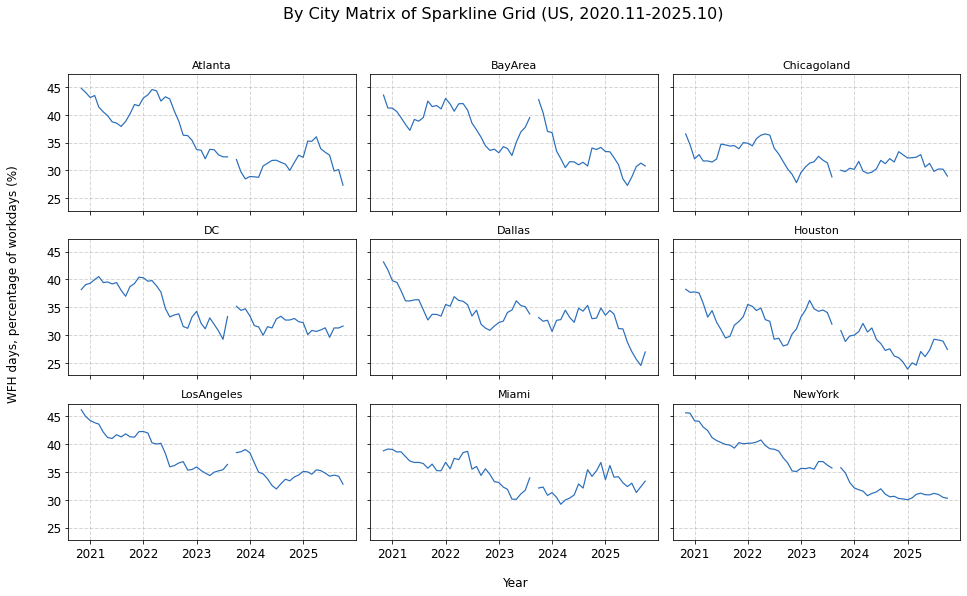

In [4]:
# Mini time-series matrix (sparkline grid) WITH axes / ticks / frame
# 帶軸、刻度、外框的小型火花線矩陣（從 2020/11/1 開始）

import pandas as pd
import matplotlib.pyplot as plt

# 1. Read data ---------------------------------------------------------------
file_path = "WFHtimeseries_monthly.xlsx"
sheet_name = "WFH by city"
df = pd.read_excel(file_path, sheet_name=sheet_name)

# 2. Date handling -----------------------------------------------------------
df["date"] = pd.to_datetime(df["date"])

# Filter dates starting from 2020-11-01                                     
df = df[df["date"] >= "2020-11-01"].sort_values("date")

# 3. City columns ------------------------------------------------------------
city_cols = [
    "wfhcovid_series_MA6_Atlanta",
    "wfhcovid_series_MA6_BayArea",
    "wfhcovid_series_MA6_Chicagoland",
    "wfhcovid_series_MA6_DC",
    "wfhcovid_series_MA6_Dallas",
    "wfhcovid_series_MA6_Houston",
    "wfhcovid_series_MA6_LosAngeles",
    "wfhcovid_series_MA6_Miami",
    "wfhcovid_series_MA6_NewYork"
]
city_labels = [c.replace("wfhcovid_series_MA6_", "") for c in city_cols]

# 4. Sparkline Grid WITH axes -----------------------------------------------
n_rows, n_cols = 3, 3
fig, axes = plt.subplots(n_rows, n_cols, figsize=(13, 8), sharex=True, sharey=True)
axes_flat = axes.ravel()

for i, (col, label) in enumerate(zip(city_cols, city_labels)):
    ax = axes_flat[i]

    ax.grid(axis="both", which="major", linestyle="--", linewidth=1, alpha=0.5)
    
    # Plot line --------------------------------------------------------------
    ax.plot(df["date"], df[col], linewidth=1.2, color="#2A6EBB")

    # Title over each subplot ------------------------------------------------
    ax.set_title(label, fontsize=11)

    # KEEP x-axis and y-axis ticks & frame                  
    ax.tick_params(axis="both", labelsize=12)   # ← 字體放大（唯一修改）

    # Rotate x labels slightly for readability                                 
    plt.setp(ax.get_xticklabels()) 

# Add X,Y-axis label
fig.text(0.5, -0.02, "Year", va="center", fontsize=12)
fig.text(-0.03, 0.5, "WFH days, percentage of workdays (%)", va="center",rotation="vertical", fontsize=12)

# Overall title --------------------------------------------------------------
fig.suptitle("By City Matrix of Sparkline Grid (US, 2020.11-2025.10)", fontsize=16)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


### By Industry (All-14)

Number of industries detected: 14


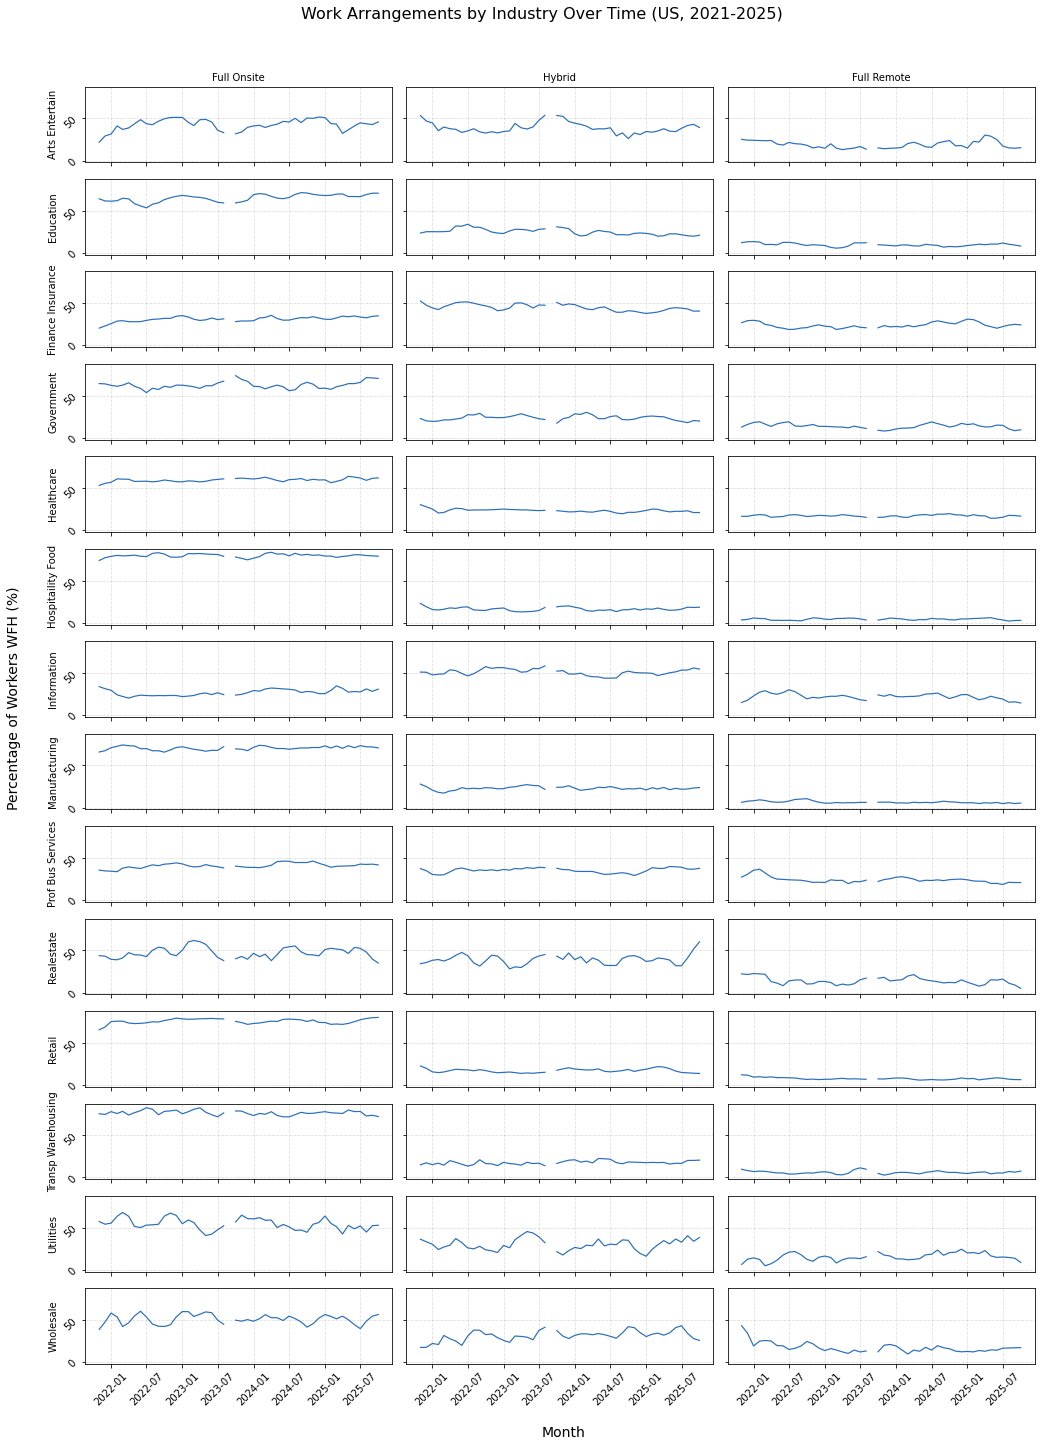

In [5]:
# Matrix of time series: columns = work arrangement (onsite / hybrid / remote),
# rows = industries (all available industries)

import pandas as pd
import matplotlib.pyplot as plt

# 1. Read data ---------------------------------------------------------------
file_path = "WFHtimeseries_monthly.xlsx"
sheet_name = "Work Arrangements by Industry"
df = pd.read_excel(file_path, sheet_name=sheet_name)

# 2. Date handling -----------------------------------------------------------
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date")

# 3. Get all industries automatically ---------------------------------------
onsite_prefix = "full_onsite_"
hybrid_prefix = "hybrid_"
remote_prefix = "full_remote_"

onsite_cols = [c for c in df.columns if c.startswith(onsite_prefix)]
industries = sorted([c.replace(onsite_prefix, "") for c in onsite_cols])

n_industries = len(industries)
print(f"Number of industries detected: {n_industries}")

# 4. Define work arrangement types ------------------------------------------
arrangements = [
    (onsite_prefix, "Full Onsite"),
    (hybrid_prefix, "Hybrid"),
    (remote_prefix, "Full Remote")
]

n_cols = len(arrangements)
n_rows = n_industries

# 5. Create subplot grid -----------------------------------------------------
fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(14, max(20, 1.3 * n_rows)),
    sharex=True, sharey=True
)

if n_rows == 1:
    axes = axes.reshape(1, -1)

# 6. Loop to draw each chart -------------------------------------------------
for row_idx, industry_suffix in enumerate(industries):
    row_label = industry_suffix.replace("_", " ").title()

    for col_idx, (prefix, col_title) in enumerate(arrangements):
        ax = axes[row_idx, col_idx]

        series_col = prefix + industry_suffix

        if series_col not in df.columns:
            ax.text(0.5, 0.5, "N/A", ha="center", va="center", fontsize=8)
            ax.set_axis_off()
            continue

        ax.plot(df["date"], df[series_col], linewidth=1.2, color="#2A6EBB")
        ax.grid(axis="both", which="major", linestyle="--", linewidth=0.8, alpha=0.4)

        if row_idx == 0:
            ax.set_title(col_title, fontsize=10)

        if col_idx == 0:
            ax.set_ylabel(row_label, fontsize=10)

        plt.setp(ax.get_xticklabels(), rotation=45)
        ax.tick_params(axis="both", rotation=45)

fig.text(0.5, -0.01, "Month", va="center", fontsize=14)
fig.text(-0.03, 0.5, "Percentage of Workers WFH (%)", va="center", rotation="vertical", fontsize=14)

# 7. Overall title -----------------------------------------------------------
fig.suptitle("Work Arrangements by Industry Over Time (US, 2021-2025)", fontsize=16)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


### By Industry (choose 6)

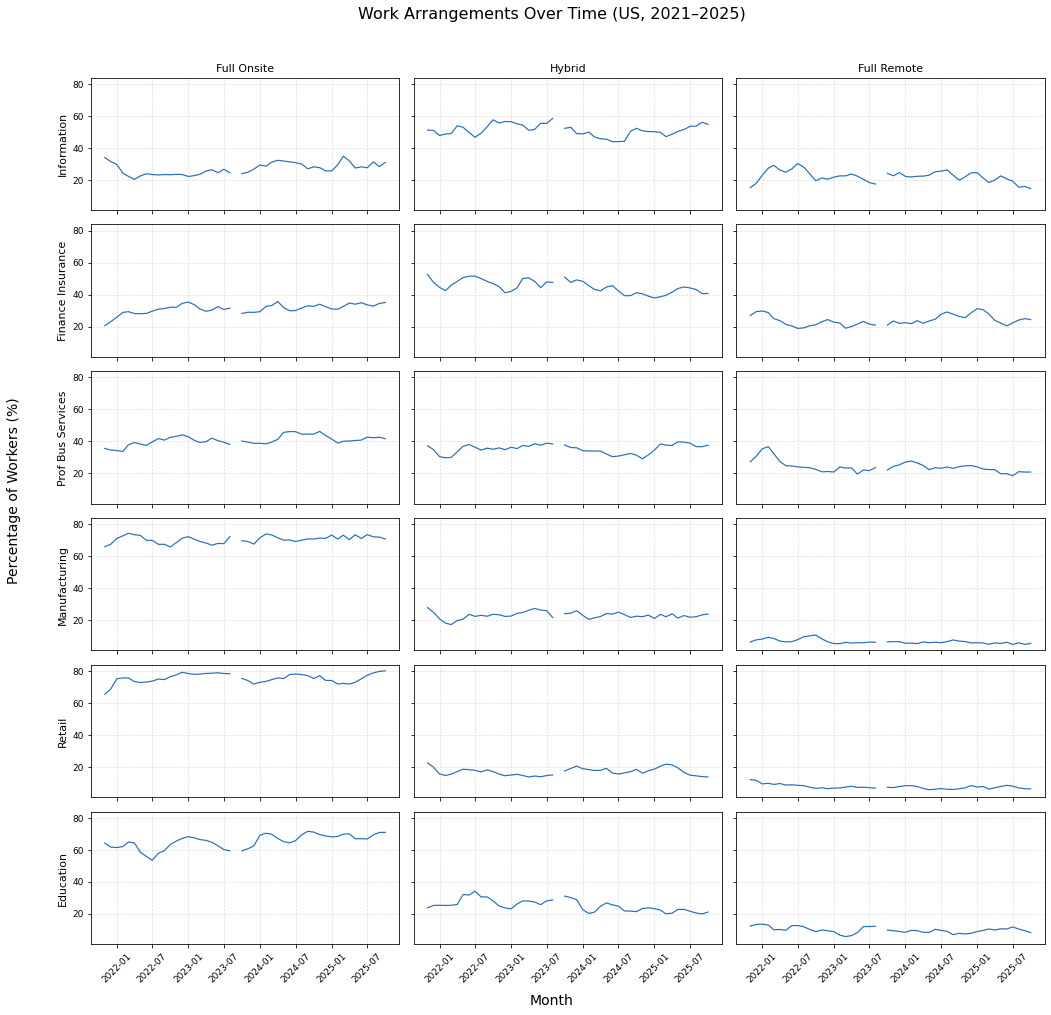

In [6]:
# Matrix of time series: columns = work arrangement (onsite / hybrid / remote),
# rows = SELECTED industries with clearest differences

import pandas as pd
import matplotlib.pyplot as plt

# 1. Read data ---------------------------------------------------------------
file_path = "WFHtimeseries_monthly.xlsx"
sheet_name = "Work Arrangements by Industry"
df = pd.read_excel(file_path, sheet_name=sheet_name)

# 2. Date handling -----------------------------------------------------------
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date")

# 3. Work arrangement column prefixes ----------------------------------------
onsite_prefix = "full_onsite_"
hybrid_prefix = "hybrid_"
remote_prefix = "full_remote_"

# 4. Define SELECTED industries ----------------------------------------------
selected_industries = [
    "information",
    "finance_insurance",
    "prof_bus_services",
    "manufacturing",
    "retail",
    "education"
]

# 5. Define work arrangement types (columns) ---------------------------------
arrangements = [
    (onsite_prefix, "Full Onsite"),
    (hybrid_prefix, "Hybrid"),
    (remote_prefix, "Full Remote")
]

n_cols = len(arrangements)
n_rows = len(selected_industries)

# 6. Create subplot grid -----------------------------------------------------
fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(14, max(14, 1.5 * n_rows)),
    sharex=True, sharey=True
)

# Ensure axes is 2D
if n_rows == 1:
    axes = axes.reshape(1, -1)

# 7. Loop to draw each chart -------------------------------------------------
for row_idx, industry_suffix in enumerate(selected_industries):
    row_label = industry_suffix.replace("_", " ").title()

    for col_idx, (prefix, col_title) in enumerate(arrangements):
        ax = axes[row_idx, col_idx]

        series_col = prefix + industry_suffix

        if series_col not in df.columns:
            ax.text(0.5, 0.5, "N/A", ha="center", va="center")
            ax.set_axis_off()
            continue

        ax.plot(df["date"], df[series_col], linewidth=1.2, color="#2A6EBB")
        ax.grid(axis="both", which="major", linestyle="--", linewidth=0.7, alpha=0.4)

        if row_idx == 0:
            ax.set_title(col_title, fontsize=11)

        if col_idx == 0:
            ax.set_ylabel(row_label, fontsize=11)

        plt.setp(ax.get_xticklabels(), rotation=45)
        ax.tick_params(axis="both", labelsize=9)

# 8. X / Y labels & title -----------------------------------------------------
fig.text(0.5, -0.01, "Month", ha="center", fontsize=14)
fig.text(-0.04, 0.5, "Percentage of Workers (%)",
         va="center", rotation="vertical", fontsize=14)

fig.suptitle("Work Arrangements Over Time (US, 2021–2025)", fontsize=16)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()
